# Aging basins — stored-results figure atlas (A04)

This executed notebook renders **no new models**. It documents and displays the A04 figure set generated solely from the checksum-verified outputs of A01–A03.

**Citations.** Tabula Muris Senis (Schaum *et al.*, 2020); scVI (Lopez *et al.*, 2018); scArches (Lotfollahi *et al.*, 2022).

In [1]:
from pathlib import Path
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from scjdo2 import plot

ROOT = Path.cwd()
AGING = ROOT / 'benchmarks' / 'aging'
FIGURES = ROOT / 'benchmarks' / 'figures' / 'aging'
manifest = pd.read_csv(FIGURES / 'MANIFEST.csv')
print(f"Manifest: {len(manifest)} rows; {manifest.path.str.endswith('.png').sum()} PNG figures")

Manifest: 159 rows; 78 PNG figures


## Preprocessing and donor balancing
The A01 processed matrices apply the frozen young/old mapping and balanced sampling before the ≥200-cells-per-age eligibility gate. The tables below are stored bookkeeping, not recomputed filtering.

In [2]:
for tissue in ('lung', 'marrow'):
    before = pd.read_csv(AGING / 'qc' / f'{tissue}_donor_type_counts_before.csv')
    after = pd.read_csv(AGING / 'qc' / f'{tissue}_donor_type_counts_after.csv')
    print(f'\n{tissue}: before={before.n_cells_before.sum():,}; after={after.n_cells_after.sum():,}')
    display(after.head())


lung: before=10,939; after=3,374


,tissue,age_group,donor_id,cell_type,n_cells_after,n_cells_contributed,eligible,downsampled_age_group
0,lung,old,18-F-50,B cell,26,26,False,old
1,lung,old,18-F-50,bronchial smooth muscle cell,25,25,False,old
2,lung,old,18-F-50,classical monocyte,18,18,False,old
3,lung,old,18-F-50,natural killer cell,27,27,True,young
4,lung,old,18-F-50,non-classical monocyte,27,27,False,old



marrow: before=23,697; after=6,886


,tissue,age_group,donor_id,cell_type,n_cells_after,n_cells_contributed,eligible,downsampled_age_group
0,marrow,old,18-F-50,erythroblast,8,8,False,old
1,marrow,old,18-F-50,granulocyte,70,70,True,old
2,marrow,old,18-F-50,granulocytopoietic cell,72,72,True,old
3,marrow,old,18-F-50,hematopoietic precursor cell,29,29,True,old
4,marrow,old,18-F-50,late pro-B cell,6,6,False,old


## scVI/scArches mapping provenance
A02 used the frozen 15-dimensional young-reference mapping; the old data were mapped with `SCVI.load_query_data`. Only the stored final validation ELBOs are available—per-epoch curves were not retained.

In [3]:
for tissue in ('lung', 'marrow'):
    metrics = pd.read_csv(AGING / 'qc' / f'{tissue}_scvi_metrics.csv')
    print(tissue); display(metrics)

lung


,fit,epochs_run,best_val_elbo,mapping_path
0,reference_young,45,1052.335571,young_reference
1,query_shared,167,939.062012,scvi.model.SCVI.load_query_data
2,standalone_old,43,990.037476,standalone_old


marrow


,fit,epochs_run,best_val_elbo,mapping_path
0,reference_young,364,945.791626,young_reference
1,query_shared,130,922.048401,scvi.model.SCVI.load_query_data
2,standalone_old,264,904.735657,standalone_old


## Symmetry and stored-drift checks
The Jacobians are the stored A02 symmetric-operator outputs. The summary below reports the already-recorded Frobenius symmetry residuals and final energy-score losses.

In [4]:
for tissue in ('lung', 'marrow'):
    print(tissue); display(pd.read_csv(AGING / 'qc' / f'{tissue}_drift_metrics.csv'))

lung


,fit,final_loss,sym_median,sym_max
0,shared,-2665.079602,1.199948e-07,2.518831e-07
1,standalone_young,-2408.228074,1.188063e-07,1.923376e-07
2,standalone_old,-2402.165404,1.297298e-07,2.021844e-07


marrow


,fit,final_loss,sym_median,sym_max
0,shared,-221.240007,5.758966e-08,1.458985e-07
1,standalone_young,-203.595097,6.070075e-08,1.172992e-07
2,standalone_old,-394.910301,5.072727e-08,8.866611e-08


## Per-type shared-space comparison
These are the locked A03 tables. `lambda_ratio_soft_axis` is interpreted only for types with young holder fraction ≥0.5; others are shown as an em dash in the summary figure.

In [5]:
tables = []
for tissue in ('lung', 'marrow'):
    tables.append(pd.read_csv(AGING / f'{tissue}_compare_shared.csv'))
compare = pd.concat(tables, ignore_index=True)
display(compare[['tissue','cell_type','n_young','n_old','iso_pass','ant_pass','basin_fraction_young','basin_fraction_old','correction_artifact']])
print('non-artifact types:', int((~compare.correction_artifact).sum()))

,tissue,cell_type,n_young,n_old,iso_pass,ant_pass,basin_fraction_young,basin_fraction_old,correction_artifact
0,lung,fibroblast of lung,263,263,False,False,0.912548,0.977186,False
1,lung,natural killer cell,385,385,False,False,0.914286,0.901299,False
2,marrow,granulocyte,704,704,False,False,0.686080,0.802557,False
3,marrow,granulocytopoietic cell,727,727,True,False,0.195323,0.436039,False
4,marrow,hematopoietic precursor cell,285,285,True,False,0.136842,0.133333,False
5,marrow,monocyte,488,488,False,False,0.061475,0.051230,False
6,marrow,precursor B cell,259,259,True,False,0.220077,0.108108,False
7,marrow,promonocyte,231,231,False,True,0.082251,0.017316,False


non-artifact types: 8


## Live plotting API audit
The following calls operate on stored shared-space arrays only and show the same plotted data used in the saved figure inventory.

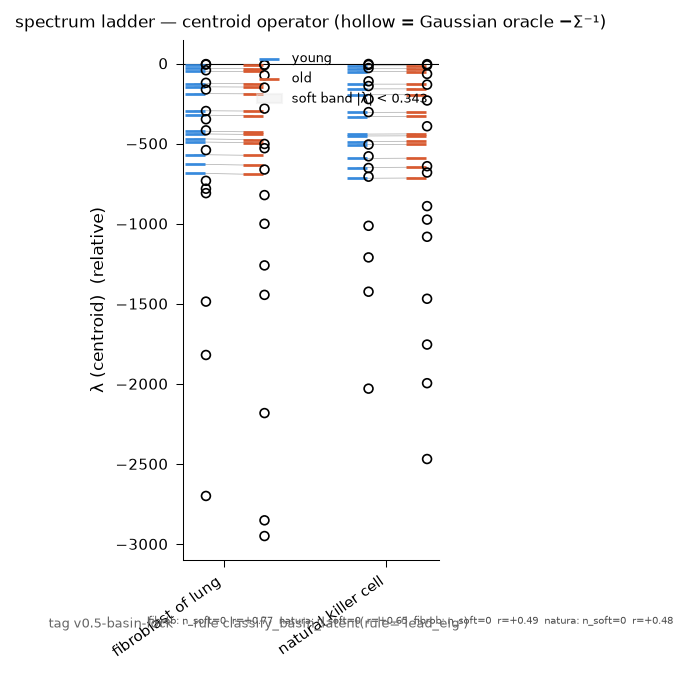

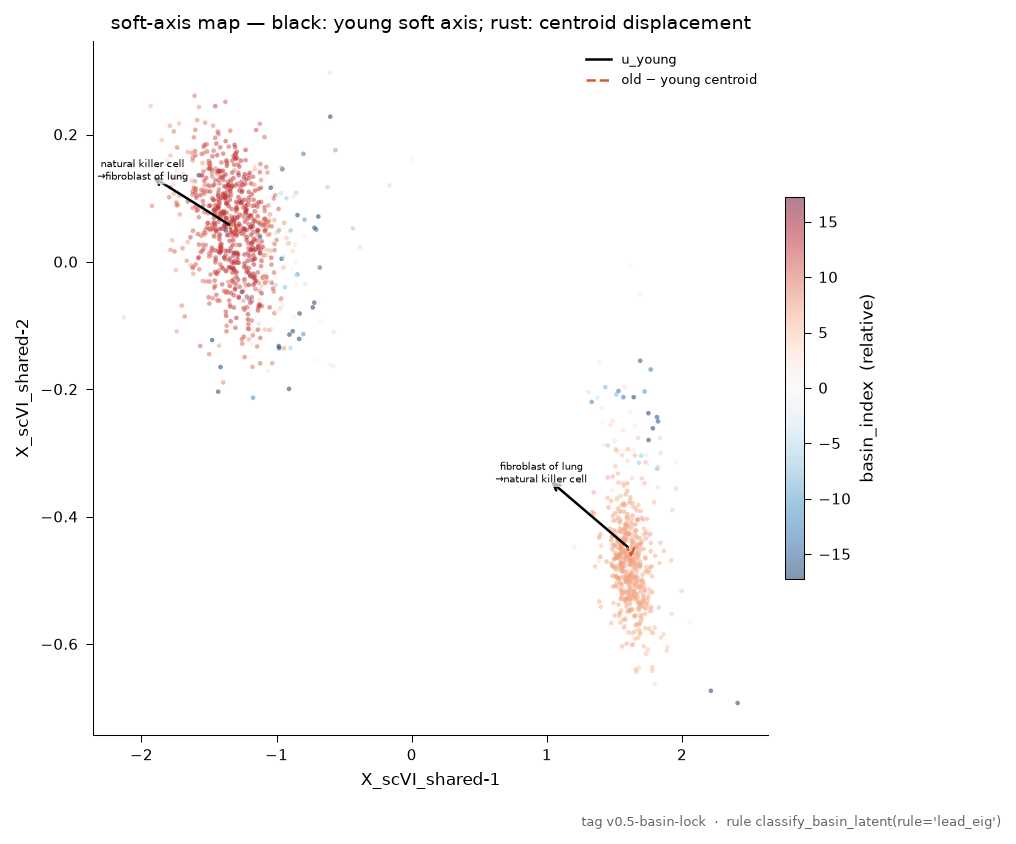

In [6]:
lung = ad.read_h5ad(AGING / 'lung_shared.h5ad')
# Display aliases use stored fields only; no fitting or parameter update occurs.
lung.obsm['X_pca'] = np.asarray(lung.obsm['X_scVI_shared'])
lung.obs['lead_re'] = -lung.obs['op_basin_index'].to_numpy(float)
lung.obs['lead_im'] = 0.0
lung.obs['op_behaviour'] = lung.obs['op_behaviour_basin'].astype(str).to_numpy()
fig = plot.spectrum_ladder(lung, by='cell_type', groups=('young','old'), use_rep='X_scVI_shared')
display(fig); plt.close(fig)
fig = plot.soft_axis_map(lung, by='cell_type', groups=('young','old'), displacement_arrow=True, use_rep='X_scVI_shared')
display(fig); plt.close(fig)

## Figure atlas
Each entry gives the manifest path, the specification item, and the frozen rule/context it represents. PNGs are linked inline; matching 200-dpi PDFs are recorded alongside them in `MANIFEST.csv`.

### `§7.5 aging_vectors` — both, young_old

**What it shows.** Stored-result rendering for the A04 item `§7.5 aging_vectors`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/compare_pooled.csv;benchmarks/aging/aging_modes.csv`.

![aging_vectors](../benchmarks/figures/aging/comparison/aging_vectors.png)

### `§7.3 basin_index_by_type` — lung, young_old

**What it shows.** Stored-result rendering for the A04 item `§7.3 basin_index_by_type`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![basin_index_age_facet](../benchmarks/figures/aging/lung/basin_index_age_facet.png)

### `§7b compare_summary` — lung, young_old

**What it shows.** Stored-result rendering for the A04 item `§7b compare_summary`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_compare_shared.csv;benchmarks/aging/aging_modes.csv`.

![compare_summary](../benchmarks/figures/aging/lung/compare_summary.png)

### `§7.6 energy_transect` — lung, young_old

**What it shows.** Stored-result rendering for the A04 item `§7.6 energy_transect`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad;benchmarks/aging/models/lung_shared_drift.pt`.

![energy_transect_fibroblast_of_lung](../benchmarks/figures/aging/lung/energy_transect_fibroblast_of_lung.png)

### `§7.6 energy_transect` — lung, young_old

**What it shows.** Stored-result rendering for the A04 item `§7.6 energy_transect`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad;benchmarks/aging/models/lung_shared_drift.pt`.

![energy_transect_natural_killer_cell](../benchmarks/figures/aging/lung/energy_transect_natural_killer_cell.png)

### `§7b basin_index_by_type single group` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b basin_index_by_type single group`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![basin_index](../benchmarks/figures/aging/lung/old/basin_index.png)

### `§7b Gaussian-oracle curvature ratio` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b Gaussian-oracle curvature ratio`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![gaussian_oracle_curvature_ratio](../benchmarks/figures/aging/lung/old/gaussian_oracle_curvature_ratio.png)

### `§7.4 ledger_map` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7.4 ledger_map`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![ledger_map](../benchmarks/figures/aging/lung/old/ledger_map.png)

### `§7b figure_ledger_summary` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b figure_ledger_summary`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![ledger_summary](../benchmarks/figures/aging/lung/old/ledger_summary.png)

### `§7b figure_operator_space` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b figure_operator_space`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![operator_space](../benchmarks/figures/aging/lung/old/operator_space.png)

### `§7b correction_artifact list` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b correction_artifact list`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_compare_shared.csv`.

![qc_correction_artifacts](../benchmarks/figures/aging/lung/old/qc_correction_artifacts.png)

### `§7b d_latent choice` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b d_latent choice`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![qc_d_latent](../benchmarks/figures/aging/lung/old/qc_d_latent.png)

### `§7b donor × type counts` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b donor × type counts`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad;benchmarks/aging/qc/lung_donor_type_counts_before.csv;benchmarks/aging/qc/lung_donor_type_counts_after.csv`.

![qc_donor_type_counts](../benchmarks/figures/aging/lung/old/qc_donor_type_counts.png)

### `§7b inter-cluster gap control` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b inter-cluster gap control`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![qc_gap](../benchmarks/figures/aging/lung/old/qc_gap.png)

### `§7b tangent-rank distribution` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b tangent-rank distribution`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![qc_rank](../benchmarks/figures/aging/lung/old/qc_rank.png)

### `§7b scVI ELBO QC` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b scVI ELBO QC`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/qc/lung_scvi_metrics.csv`.

![qc_scvi_elbo_summary](../benchmarks/figures/aging/lung/old/qc_scvi_elbo_summary.png)

### `§7b standalone-versus-shared basin agreement` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b standalone-versus-shared basin agreement`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad;benchmarks/aging/lung_standalone_old.h5ad`.

![qc_shared_standalone_basin_confusion](../benchmarks/figures/aging/lung/old/qc_shared_standalone_basin_confusion.png)

### `§7b within-cluster σ versus drift scale` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b within-cluster σ versus drift scale`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![qc_sigma](../benchmarks/figures/aging/lung/old/qc_sigma.png)

### `§7b symmetry check histogram` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b symmetry check histogram`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![qc_symmetry](../benchmarks/figures/aging/lung/old/qc_symmetry.png)

### `§7b soft_axis_map` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b soft_axis_map`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![soft_axis_map](../benchmarks/figures/aging/lung/old/soft_axis_map.png)

### `§7b spectrum_ladder single group` — lung, old

**What it shows.** Stored-result rendering for the A04 item `§7b spectrum_ladder single group`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![spectrum_ladder](../benchmarks/figures/aging/lung/old/spectrum_ladder.png)

### `§7.2 soft_axis_map displacement` — lung, young_old

**What it shows.** Stored-result rendering for the A04 item `§7.2 soft_axis_map displacement`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![soft_axis_map_young_old](../benchmarks/figures/aging/lung/soft_axis_map_young_old.png)

### `§7.1 spectrum_ladder groups` — lung, young_old

**What it shows.** Stored-result rendering for the A04 item `§7.1 spectrum_ladder groups`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![spectrum_ladder_young_old](../benchmarks/figures/aging/lung/spectrum_ladder_young_old.png)

### `§7b standalone-versus-shared quantities` — lung, young_old

**What it shows.** Stored-result rendering for the A04 item `§7b standalone-versus-shared quantities`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_compare_standalone.csv`.

![standalone_shared_quantities](../benchmarks/figures/aging/lung/standalone_shared_quantities.png)

### `§7b basin_index_by_type single group` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b basin_index_by_type single group`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![basin_index](../benchmarks/figures/aging/lung/young/basin_index.png)

### `§7b Gaussian-oracle curvature ratio` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b Gaussian-oracle curvature ratio`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![gaussian_oracle_curvature_ratio](../benchmarks/figures/aging/lung/young/gaussian_oracle_curvature_ratio.png)

### `§7.4 ledger_map` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7.4 ledger_map`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![ledger_map](../benchmarks/figures/aging/lung/young/ledger_map.png)

### `§7b figure_ledger_summary` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b figure_ledger_summary`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![ledger_summary](../benchmarks/figures/aging/lung/young/ledger_summary.png)

### `§7b figure_operator_space` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b figure_operator_space`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![operator_space](../benchmarks/figures/aging/lung/young/operator_space.png)

### `§7b correction_artifact list` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b correction_artifact list`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_compare_shared.csv`.

![qc_correction_artifacts](../benchmarks/figures/aging/lung/young/qc_correction_artifacts.png)

### `§7b d_latent choice` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b d_latent choice`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![qc_d_latent](../benchmarks/figures/aging/lung/young/qc_d_latent.png)

### `§7b donor × type counts` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b donor × type counts`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad;benchmarks/aging/qc/lung_donor_type_counts_before.csv;benchmarks/aging/qc/lung_donor_type_counts_after.csv`.

![qc_donor_type_counts](../benchmarks/figures/aging/lung/young/qc_donor_type_counts.png)

### `§7b inter-cluster gap control` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b inter-cluster gap control`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![qc_gap](../benchmarks/figures/aging/lung/young/qc_gap.png)

### `§7b tangent-rank distribution` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b tangent-rank distribution`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![qc_rank](../benchmarks/figures/aging/lung/young/qc_rank.png)

### `§7b scVI ELBO QC` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b scVI ELBO QC`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/qc/lung_scvi_metrics.csv`.

![qc_scvi_elbo_summary](../benchmarks/figures/aging/lung/young/qc_scvi_elbo_summary.png)

### `§7b standalone-versus-shared basin agreement` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b standalone-versus-shared basin agreement`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad;benchmarks/aging/lung_standalone_young.h5ad`.

![qc_shared_standalone_basin_confusion](../benchmarks/figures/aging/lung/young/qc_shared_standalone_basin_confusion.png)

### `§7b within-cluster σ versus drift scale` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b within-cluster σ versus drift scale`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![qc_sigma](../benchmarks/figures/aging/lung/young/qc_sigma.png)

### `§7b symmetry check histogram` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b symmetry check histogram`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![qc_symmetry](../benchmarks/figures/aging/lung/young/qc_symmetry.png)

### `§7b soft_axis_map` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b soft_axis_map`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![soft_axis_map](../benchmarks/figures/aging/lung/young/soft_axis_map.png)

### `§7b spectrum_ladder single group` — lung, young

**What it shows.** Stored-result rendering for the A04 item `§7b spectrum_ladder single group`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/lung_shared.h5ad`.

![spectrum_ladder](../benchmarks/figures/aging/lung/young/spectrum_ladder.png)

### `§7.3 basin_index_by_type` — marrow, young_old

**What it shows.** Stored-result rendering for the A04 item `§7.3 basin_index_by_type`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![basin_index_age_facet](../benchmarks/figures/aging/marrow/basin_index_age_facet.png)

### `§7b compare_summary` — marrow, young_old

**What it shows.** Stored-result rendering for the A04 item `§7b compare_summary`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_compare_shared.csv;benchmarks/aging/aging_modes.csv`.

![compare_summary](../benchmarks/figures/aging/marrow/compare_summary.png)

### `§7.6 energy_transect` — marrow, young_old

**What it shows.** Stored-result rendering for the A04 item `§7.6 energy_transect`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad;benchmarks/aging/models/marrow_shared_drift.pt`.

![energy_transect_granulocyte](../benchmarks/figures/aging/marrow/energy_transect_granulocyte.png)

### `§7b basin_index_by_type single group` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b basin_index_by_type single group`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![basin_index](../benchmarks/figures/aging/marrow/old/basin_index.png)

### `§7b Gaussian-oracle curvature ratio` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b Gaussian-oracle curvature ratio`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![gaussian_oracle_curvature_ratio](../benchmarks/figures/aging/marrow/old/gaussian_oracle_curvature_ratio.png)

### `§7.4 ledger_map` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7.4 ledger_map`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![ledger_map](../benchmarks/figures/aging/marrow/old/ledger_map.png)

### `§7b figure_ledger_summary` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b figure_ledger_summary`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![ledger_summary](../benchmarks/figures/aging/marrow/old/ledger_summary.png)

### `§7b figure_operator_space` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b figure_operator_space`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![operator_space](../benchmarks/figures/aging/marrow/old/operator_space.png)

### `§7b correction_artifact list` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b correction_artifact list`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_compare_shared.csv`.

![qc_correction_artifacts](../benchmarks/figures/aging/marrow/old/qc_correction_artifacts.png)

### `§7b d_latent choice` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b d_latent choice`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![qc_d_latent](../benchmarks/figures/aging/marrow/old/qc_d_latent.png)

### `§7b donor × type counts` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b donor × type counts`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad;benchmarks/aging/qc/marrow_donor_type_counts_before.csv;benchmarks/aging/qc/marrow_donor_type_counts_after.csv`.

![qc_donor_type_counts](../benchmarks/figures/aging/marrow/old/qc_donor_type_counts.png)

### `§7b inter-cluster gap control` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b inter-cluster gap control`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![qc_gap](../benchmarks/figures/aging/marrow/old/qc_gap.png)

### `§7b tangent-rank distribution` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b tangent-rank distribution`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![qc_rank](../benchmarks/figures/aging/marrow/old/qc_rank.png)

### `§7b scVI ELBO QC` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b scVI ELBO QC`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/qc/marrow_scvi_metrics.csv`.

![qc_scvi_elbo_summary](../benchmarks/figures/aging/marrow/old/qc_scvi_elbo_summary.png)

### `§7b standalone-versus-shared basin agreement` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b standalone-versus-shared basin agreement`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad;benchmarks/aging/marrow_standalone_old.h5ad`.

![qc_shared_standalone_basin_confusion](../benchmarks/figures/aging/marrow/old/qc_shared_standalone_basin_confusion.png)

### `§7b within-cluster σ versus drift scale` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b within-cluster σ versus drift scale`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![qc_sigma](../benchmarks/figures/aging/marrow/old/qc_sigma.png)

### `§7b symmetry check histogram` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b symmetry check histogram`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![qc_symmetry](../benchmarks/figures/aging/marrow/old/qc_symmetry.png)

### `§7b soft_axis_map` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b soft_axis_map`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![soft_axis_map](../benchmarks/figures/aging/marrow/old/soft_axis_map.png)

### `§7b spectrum_ladder single group` — marrow, old

**What it shows.** Stored-result rendering for the A04 item `§7b spectrum_ladder single group`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![spectrum_ladder](../benchmarks/figures/aging/marrow/old/spectrum_ladder.png)

### `§7.2 soft_axis_map displacement` — marrow, young_old

**What it shows.** Stored-result rendering for the A04 item `§7.2 soft_axis_map displacement`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![soft_axis_map_young_old](../benchmarks/figures/aging/marrow/soft_axis_map_young_old.png)

### `§7.1 spectrum_ladder groups` — marrow, young_old

**What it shows.** Stored-result rendering for the A04 item `§7.1 spectrum_ladder groups`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![spectrum_ladder_young_old](../benchmarks/figures/aging/marrow/spectrum_ladder_young_old.png)

### `§7b standalone-versus-shared quantities` — marrow, young_old

**What it shows.** Stored-result rendering for the A04 item `§7b standalone-versus-shared quantities`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_compare_standalone.csv`.

![standalone_shared_quantities](../benchmarks/figures/aging/marrow/standalone_shared_quantities.png)

### `§7b basin_index_by_type single group` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b basin_index_by_type single group`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![basin_index](../benchmarks/figures/aging/marrow/young/basin_index.png)

### `§7b Gaussian-oracle curvature ratio` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b Gaussian-oracle curvature ratio`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![gaussian_oracle_curvature_ratio](../benchmarks/figures/aging/marrow/young/gaussian_oracle_curvature_ratio.png)

### `§7.4 ledger_map` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7.4 ledger_map`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![ledger_map](../benchmarks/figures/aging/marrow/young/ledger_map.png)

### `§7b figure_ledger_summary` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b figure_ledger_summary`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![ledger_summary](../benchmarks/figures/aging/marrow/young/ledger_summary.png)

### `§7b figure_operator_space` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b figure_operator_space`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![operator_space](../benchmarks/figures/aging/marrow/young/operator_space.png)

### `§7b correction_artifact list` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b correction_artifact list`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_compare_shared.csv`.

![qc_correction_artifacts](../benchmarks/figures/aging/marrow/young/qc_correction_artifacts.png)

### `§7b d_latent choice` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b d_latent choice`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![qc_d_latent](../benchmarks/figures/aging/marrow/young/qc_d_latent.png)

### `§7b donor × type counts` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b donor × type counts`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad;benchmarks/aging/qc/marrow_donor_type_counts_before.csv;benchmarks/aging/qc/marrow_donor_type_counts_after.csv`.

![qc_donor_type_counts](../benchmarks/figures/aging/marrow/young/qc_donor_type_counts.png)

### `§7b inter-cluster gap control` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b inter-cluster gap control`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![qc_gap](../benchmarks/figures/aging/marrow/young/qc_gap.png)

### `§7b tangent-rank distribution` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b tangent-rank distribution`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![qc_rank](../benchmarks/figures/aging/marrow/young/qc_rank.png)

### `§7b scVI ELBO QC` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b scVI ELBO QC`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/qc/marrow_scvi_metrics.csv`.

![qc_scvi_elbo_summary](../benchmarks/figures/aging/marrow/young/qc_scvi_elbo_summary.png)

### `§7b standalone-versus-shared basin agreement` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b standalone-versus-shared basin agreement`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad;benchmarks/aging/marrow_standalone_young.h5ad`.

![qc_shared_standalone_basin_confusion](../benchmarks/figures/aging/marrow/young/qc_shared_standalone_basin_confusion.png)

### `§7b within-cluster σ versus drift scale` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b within-cluster σ versus drift scale`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![qc_sigma](../benchmarks/figures/aging/marrow/young/qc_sigma.png)

### `§7b symmetry check histogram` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b symmetry check histogram`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![qc_symmetry](../benchmarks/figures/aging/marrow/young/qc_symmetry.png)

### `§7b soft_axis_map` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b soft_axis_map`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![soft_axis_map](../benchmarks/figures/aging/marrow/young/soft_axis_map.png)

### `§7b spectrum_ladder single group` — marrow, young

**What it shows.** Stored-result rendering for the A04 item `§7b spectrum_ladder single group`.  **Frozen rule/context.** v0.5 basin lock; `classify_basin_latent(rule='lead_eig')`; shared scArches space where applicable.  **Source files.** `benchmarks/aging/marrow_shared.h5ad`.

![spectrum_ladder](../benchmarks/figures/aging/marrow/young/spectrum_ladder.png)

## Deviations
The three no-refit deviations are intentionally documented rather than approximated or simulated.

In [7]:
print((FIGURES / 'DEVIATIONS.md').read_text())

# A04 rendering deviations

* `figure_archetype_sheet` was not rendered: no stored archetype weights exist, and A04 prohibits the requested semi-NMF fitting.
* The ten-refit `lead_re` permutation-null panel was not rendered: no such refits are stored, and recreating them would violate the no-refit instruction.
* Per-epoch scVI ELBO curves were not stored by A02. The rendered QC panels show the stored best validation ELBO summaries instead.



## Frozen outcome
The outcome header below is copied verbatim from A03 and is not reinterpreted in A04.

In [8]:
outcome_header = 'isotropic noise increase; no aging claim beyond stiffness'
print(outcome_header)

isotropic noise increase; no aging claim beyond stiffness
